### Simple  QnA Bot  Without Langchain - With Groq

In [1]:
from groq import Groq

client = Groq()
completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{
        "role" : "user" ,
        "content":"Explain Me Gen  Ai"
    }],
 
    max_completion_tokens=1000,
   
)
# detail_Ans= completion.choices[0]
# detail_Ans
# here some  tokens  are used in the  reasoning and  while some are used in the Response  of Answer Generating
completion.choices[0].message.content


# 


'## What “Gen‑AI” (Generative AI) Actually Means  \n\n**Generative AI**\u202f—\u202foften shortened to **Gen‑AI**—is a branch of artificial intelligence that can **create new content** rather than just analyze or classify what already exists. Think of it as a very advanced “creative assistant”: it can write text, draw pictures, compose music, design 3‑D objects, write code, and even generate realistic‑looking videos, all from a simple prompt you give it.\n\n| **Aspect** | **What it is** | **Typical Output** |\n|------------|----------------|--------------------|\n| **Text generation** | Large language models (LLMs) trained on billions of words | Articles, poems, chat replies, code snippets |\n| **Image generation** | Diffusion models, GANs, or transformer‑based vision models | Photorealistic pictures, illustrations, avatars |\n| **Audio & music** | Neural synths, diffusion or transformer models for waveforms | Songs, sound effects, voice‑overs |\n| **Video** | Temporal diffusion / tran

### Now Using The Similar Bot Using the Langchain
  

In [2]:
from langchain_groq import ChatGroq

llm =ChatGroq(
    model="openai/gpt-oss-120b"
)

In [3]:
# model calling 

Ans = llm.invoke("helllo how's U")
Ans


AIMessage(content="Hello! I'm doing great, thanks for asking. How can I help you today?", additional_kwargs={'reasoning_content': 'The user says "helllo how\'s U". It\'s a casual greeting. We need to respond. There\'s no policy violation. Just be friendly. Use appropriate tone. Probably respond: "Hello! I\'m doing well, thanks. How can I help you today?"'}, response_metadata={'token_usage': {'completion_tokens': 79, 'prompt_tokens': 76, 'total_tokens': 155, 'completion_time': 0.170970727, 'completion_tokens_details': {'reasoning_tokens': 53}, 'prompt_time': 0.015791658, 'prompt_tokens_details': None, 'queue_time': 0.379749777, 'total_time': 0.186762385}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c800245357', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e9d1-ed70-77e2-8aa1-9cb946222b91-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens': 79, 'total_tokens'

In [4]:
len(Ans.content)

68

In [5]:
Ans.response_metadata.get("token_usage")

{'completion_tokens': 79,
 'prompt_tokens': 76,
 'total_tokens': 155,
 'completion_time': 0.170970727,
 'completion_tokens_details': {'reasoning_tokens': 53},
 'prompt_time': 0.015791658,
 'prompt_tokens_details': None,
 'queue_time': 0.379749777,
 'total_time': 0.186762385}

### Common LLM  Calls with   `init_chat_model `

The easiest way to get started with a standalone model in LangChain is to use init_chat_model to initialize one from a chat model provider of your choice (examples below):

In [6]:
from langchain.chat_models import init_chat_model

##  Here  we Donot Need   to define the to every llm   there  Provider Source    `Chat_OpenAi    Chat_Groq`

In [7]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

### When  we  want to define  Model_Name and  Model Provider_Globaly
 So we  Can Define  it the Env  File  then  load  from it

In [3]:
#  code
import os
from dotenv import load_dotenv

load_dotenv()


from langchain.chat_models  import init_chat_model

llm_global = init_chat_model(model= os.getenv('MODEL') ,
model_provider=os.getenv('MODEL_PROVIDER')
)
# print(llm_global)
Ans= llm_global.invoke("I am Hashir Ahmad  and  u")

Ans.content

'Hello Hashir! 👋 I’m ChatGPT, your friendly AI assistant. How can I help you today? If you have a question, need some info, or just want to chat, feel free to let me know!'

In [ ]:
from langchain.chat_models import init_chat_model

# Syntax  => model = provider_name : model_ID

Model = "groq:openai/gpt-oss-120b"

llm = init_chat_model(
    Model,
    # model_provider="groq"
)

response = llm.invoke("Can you help me?")
print(response.content)

Sure! I’m happy to help. What do you need assistance with?


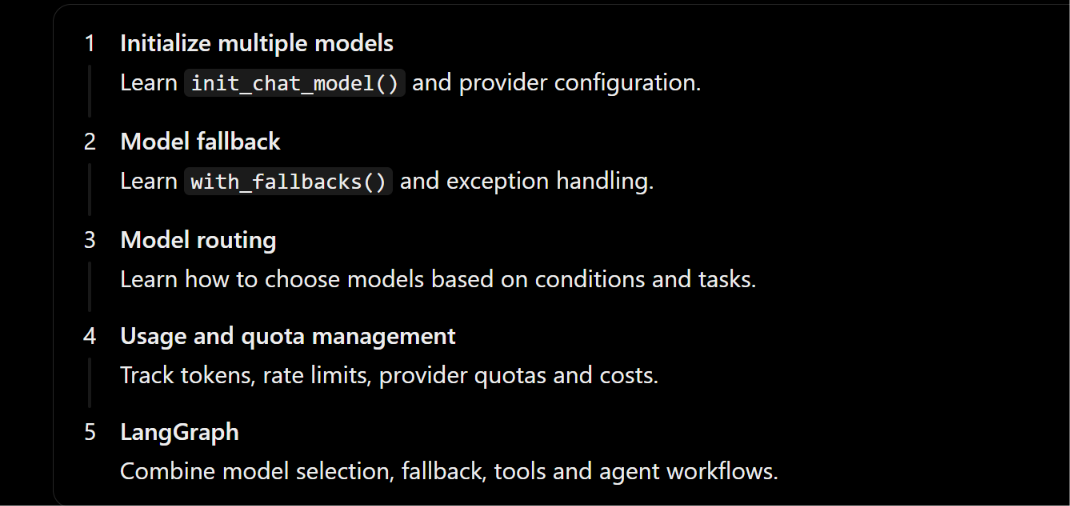

### 3. Implement fallback using LangChain
Here is a practical example:


What happens here?
1. LangChain tries OpenAI first.
2. If OpenAI raises an exception, it tries Gemini.
3. If Gemini also raises an exception, it tries Groq.
4. If all models fail, the error is returned to your application.
This is called a fallback chain.

One important detail: with_fallbacks() reacts to exceptions. It does not automatically monitor your token balance or switch just because a model is approaching its quota.
#### 4. What if you specifically want to check token limits?
There are three different situations. You should handle them differently.
Situation	Meaning	Recommended solution

`API rate` limit	Too many requests or tokens consumed within a time window	Retry or fallback

`API quota exhausted `	Provider's available usage or credits are exhausted	Switch to another provider

`Context window exceeded `	Input conversation is too large for the model	Reduce or summarize context

` Output token limit reached `	Model stopped generating because it reached its output limit	Increase output limit or continue generation

For example, if OpenAI returns a rate-limit error (often HTTP 429), you can try Gemini.

But if your conversation exceeds GPT's context window, simply switching providers might not solve the problem. You may need to summarize or reduce the conversation first.

In [ ]:
# from langchain.chat_models import init_chat_model

# # Primary model
# openai_model = init_chat_model(
#     "gpt-4o",
#     model_provider="openai"
# )

# # First fallback
# gemini_model = init_chat_model(
#     "gemini-2.5-flash",
#     model_provider="google_genai"
# )

# # Second fallback
# groq_model = init_chat_model(
#     "llama-3.1-8b-instant",
#     model_provider="groq"
# )

# # Configure fallback sequence
# llm = openai_model.with_fallbacks(
#     [gemini_model, groq_model]
# )

# # Use the model
# response = llm.invoke(
#     "Explain how AI agents work"
# )

# print(response.content)